# Arrays, measurements and linear systems

Can two detector channels recover the amounts of two components in a mixture, and when should we distrust the recovered amounts?

Winter 2026.


# Arrays and measurements
All data are synthetic. Predict the first detector signal for a 2 mM/1 mM mixture before running. Write the unit calculation and label the two axes of each array.

In [1]:
import numpy as np
from demo import RESPONSE, CONCENTRATIONS, measure, recover
print("C shape:", CONCENTRATIONS.shape, "A shape:", RESPONSE.shape)
signals = measure(CONCENTRATIONS)
print(signals)

C shape: (3, 2) A shape: (2, 2)
[[2.25  1.6  ]
 [1.25  3.7  ]
 [1.875 2.1  ]]


Interpret: which entry corresponds to specimen 2 and channel 1? Modify one specimen, then predict the affected row before recomputing. A row represents a specimen throughout this notebook.

In [2]:
recovered = recover(signals)
residual = measure(recovered) - signals
print("Recovered concentrations (mM):", recovered)
print("Maximum signal residual (AU):", np.max(np.abs(residual)))

Recovered concentrations (mM): [[2.  1. ]
 [0.5 3. ]
 [1.5 1.5]]
Maximum signal residual (AU): 2.220446049250313e-16


Predict: will the same small signal perturbation have the same effect for two almost identical channels? Run the full demonstration and compare amount errors with residuals. The perturbation is a designed synthetic experiment, not a measured noise distribution.

In [3]:
from demo import run
report = run()
for case in report["comparisons"]:
    print(case["label"], "amount error:", case["concentration_error"], "residual:", case["residual_norm"])

Distinct channels amount error: [0.0012608695652174262, -0.0010434782608692572] residual: 4.965068306494546e-16
Nearly redundant channels amount error: [0.20099999999999962, -0.19999999999999996] residual: 6.280369834735101e-16


Inspect the two figures regenerated by run(). Identify the specimen, component and channel axes before interpreting the matrix product. Then compare the same signal perturbation across the two channel designs; a tiny residual alone does not guarantee accurate recovered concentrations.

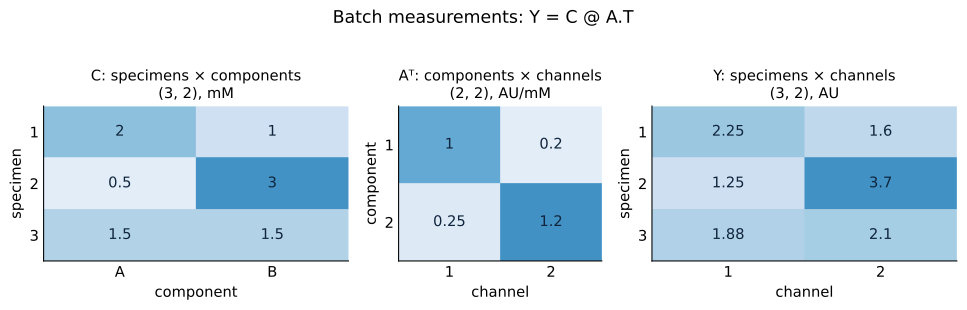

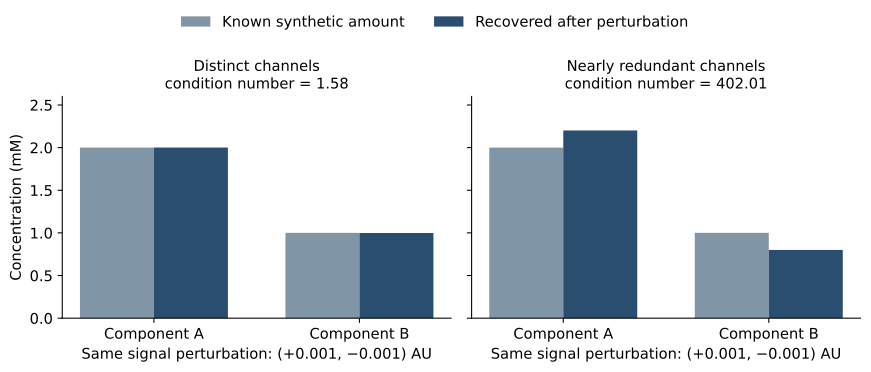

In [4]:
from IPython.display import SVG, display
display(SVG(filename="mixture-shapes.svg"))
display(SVG(filename="sensitivity.svg"))

Modify one channel coefficient and repeat a known-truth recovery experiment. State what changed, what stayed fixed, and which check supports your conclusion. Leave singular matrices as a reported limitation rather than hiding the failure.